# AR Supermarket Disruption Figures

Focused workflow for **Saturday 2024-03-30 vs baseline Saturdays**.

This notebook:
1. Loads the matched stays output
2. Merges POI names from the California POI GeoJSON
3. Prepares Saturday baseline vs storm-day subsets
4. Builds hourly visits and dwell figures
5. Computes store-level `% change in visits`, `% change in dwell`, and a combined disruption index
6. Makes two-panel and single-panel map figures with optional FFW and rain overlays

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from matplotlib.path import Path
import urllib3
import json
import xarray as xr
import shapefile


# ---------- PATHS ----------
base = "/glade/work/jcelis/code/jcelis/2.mobility_code/POI_analysis/POIs_output_v5_05march2026/supermarket_baseline_rg0_All"
poi_path = "/glade/campaign/cisl/aiml/cat_flood/ancillary_data/POIs/California_filtered_pois.geojson"
rain_path = "/glade/campaign/cisl/aiml/cat_flood/mrms/raw/mrms_precip_daily.nc"

storm_day = pd.Timestamp("2024-03-30")
counties = ["Los Angeles", "Ventura", "Santa Barbara"]
alpha = 0.5  # disruption index weight

print(base)
print(poi_path)
print(rain_path)
print("storm_day:", storm_day.date())

/glade/work/jcelis/code/jcelis/2.mobility_code/POI_analysis/POIs_output_v5_05march2026/supermarket_baseline_rg0_All
/glade/campaign/cisl/aiml/cat_flood/ancillary_data/POIs/California_filtered_pois.geojson
/glade/campaign/cisl/aiml/cat_flood/mrms/raw/mrms_precip_daily.nc
storm_day: 2024-03-30


In [2]:
# ---------- HELPERS ----------
def hourly_visits_by_county(df, county_name=None, storm_day=pd.Timestamp("2024-03-30"), weekday=5, smooth=True):
    d = df.copy()
    if county_name:
        d = d[d["county"] == county_name]

    subset = d[d["day"].dt.weekday == weekday].copy()
    storm = subset[subset["day"] == storm_day]
    baseline = subset[subset["day"] != storm_day]

    baseline_hour = (
        baseline.groupby("hour")["uid"].count() / max(baseline["day"].nunique(), 1)
    ).reindex(range(24), fill_value=0)

    storm_hour = (
        storm.groupby("hour")["uid"].count()
    ).reindex(range(24), fill_value=0)

    if smooth:
        baseline_hour = baseline_hour.rolling(3, center=True, min_periods=1).mean()
        storm_hour = storm_hour.rolling(3, center=True, min_periods=1).mean()

    return baseline_hour, storm_hour


def hourly_dwell_by_county(df, county_name=None, storm_day=pd.Timestamp("2024-03-30"), weekday=5, smooth=True):
    d = df.copy()
    if county_name:
        d = d[d["county"] == county_name]

    subset = d[d["day"].dt.weekday == weekday].copy()
    storm = subset[subset["day"] == storm_day]
    baseline = subset[subset["day"] != storm_day]

    baseline_hour = baseline.groupby("hour")["duration_min"].mean().reindex(range(24), fill_value=0)
    storm_hour = storm.groupby("hour")["duration_min"].mean().reindex(range(24), fill_value=0)

    if smooth:
        baseline_hour = baseline_hour.rolling(3, center=True, min_periods=1).mean()
        storm_hour = storm_hour.rolling(3, center=True, min_periods=1).mean()

    return baseline_hour, storm_hour


def plot_hourly_panels(df, metric="visits", storm_day=pd.Timestamp("2024-03-30"), weekday=5):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=False)
    panel_defs = [("All Counties", None)] + [(c, c) for c in counties]

    for ax, (title, county_name) in zip(axes.flatten(), panel_defs):
        if metric == "visits":
            b, s = hourly_visits_by_county(df, county_name, storm_day, weekday, smooth=True)
            ylabel = "Visits"
            panel_title = f"Hourly Supermarket Visits: Baseline vs Storm {'Saturday' if weekday == 5 else 'Friday'}"
        else:
            b, s = hourly_dwell_by_county(df, county_name, storm_day, weekday, smooth=True)
            ylabel = "Avg Dwell Time (min)"
            panel_title = f"Hourly Dwell Time: Baseline vs Storm {'Saturday' if weekday == 5 else 'Friday'}"

        label_base = f"Baseline {'Saturdays' if weekday == 5 else 'Fridays'}"
        label_storm = f"Storm {'Saturday' if weekday == 5 else 'Friday'}"

        ax.plot(b.index, b.values, color="steelblue", linewidth=3, marker="o", label=label_base)
        ax.plot(s.index, s.values, color="tomato", linewidth=3, marker="o", label=label_storm)

        ax.set_title(title, fontsize=13, weight="bold")
        ax.set_xticks(range(0, 24, 2))
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    axes[0, 0].legend(frameon=False)
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    for ax in axes[1, :]:
        ax.set_xlabel("Hour of Day")

    fig.suptitle(panel_title, fontsize=16, weight="bold")
    plt.tight_layout()
    plt.show()


def build_store_metrics(df, storm_day=pd.Timestamp("2024-03-30"), weekday=5):
    subset = df[df["day"].dt.weekday == weekday].copy()
    storm = subset[subset["day"] == storm_day].copy()
    baseline = subset[subset["day"] != storm_day].copy()

    n_baseline_days = baseline["day"].nunique()
    eps = 1e-6

    storm_store = (
        storm.groupby(["poi_id", "name", "county", "poi_lat", "poi_lon"], dropna=False)
        .agg(
            storm_visits=("uid", "count"),
            storm_dwell=("duration_min", "mean")
        )
    )

    baseline_store = (
        baseline.groupby(["poi_id", "name", "county", "poi_lat", "poi_lon"], dropna=False)
        .agg(
            baseline_total_visits=("uid", "count"),
            baseline_dwell=("duration_min", "mean")
        )
    )

    out = pd.concat([storm_store, baseline_store], axis=1).reset_index()
    out["baseline_visits"] = out["baseline_total_visits"] / max(n_baseline_days, 1)

    out["storm_visits"] = out["storm_visits"].fillna(0)
    out["storm_dwell"] = out["storm_dwell"].fillna(np.nan)
    out["baseline_visits"] = out["baseline_visits"].fillna(0)
    out["baseline_dwell"] = out["baseline_dwell"].fillna(np.nan)

    out["pct_change_visits"] = 100 * ((out["storm_visits"] - out["baseline_visits"]) / (out["baseline_visits"] + eps))
    out["pct_change_dwell"] = 100 * ((out["storm_dwell"] - out["baseline_dwell"]) / (out["baseline_dwell"] + eps))

    out["pct_change_visits_clip"] = out["pct_change_visits"].clip(-100, 100)
    out["pct_change_dwell_clip"] = out["pct_change_dwell"].clip(-100, 100)

    out["delta_visits"] = (out["storm_visits"] - out["baseline_visits"]) / (out["baseline_visits"] + eps)
    out["delta_dwell"] = (out["storm_dwell"] - out["baseline_dwell"]) / (out["baseline_dwell"] + eps)
    out["disruption_index"] = alpha * out["delta_visits"] + (1 - alpha) * out["delta_dwell"]
    out["disruption_index_clip"] = out["disruption_index"].clip(-1, 1)

    return out, n_baseline_days


def draw_overlays(ax):
    if "county_shapes" in globals():
        for county_shape in county_shapes:
            county_coords = np.array(county_shape.points).T
            ax.plot(county_coords[0], county_coords[1], color="k", linestyle="--", linewidth=0.7, zorder=2)

    for ffw in ffws["events"]["features"]:
        try:
            coords = np.array(ffw["geometry"]["coordinates"][0][0])
            ax.fill(coords[:, 0], coords[:, 1],
                    facecolor="royalblue", edgecolor="royalblue",
                    alpha=0.12, linewidth=1.0, zorder=1)
        except Exception:
            pass

    rain_field = gaussian_filter(
        rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30").values / 25.4, 1
    )
    rain_cont = ax.contour(
        rain_ds["lon"].values - 360,
        rain_ds["lat"].values,
        rain_field,
        levels=[1.0, 1.5, 2.0, 2.5, 3.0],
        cmap="plasma",
        linewidths=1.0,
        zorder=2
    )
    ax.clabel(rain_cont, fontsize=6)

    ax.set_xlim(-120.7, -117.4)
    ax.set_ylim(33.65, 35.15)
    ax.set_facecolor("0.7")


In [3]:
def hourly_dwell_by_county(df, county_name=None, storm_day=pd.Timestamp("2024-03-30"), weekday=5, smooth=True):
    d = df.copy()
    if county_name:
        d = d[d["county"] == county_name]

    subset = d[d["day"].dt.weekday == weekday].copy()
    storm = subset[subset["day"] == storm_day]
    baseline = subset[subset["day"] != storm_day]

    baseline_hour = baseline.groupby("hour")["duration_min"].mean().reindex(range(24), fill_value=0)
    baseline_05 = baseline.groupby("hour")["duration_min"].quantile(0.05).reindex(range(24), fill_value=0)
    baseline_95 = baseline.groupby("hour")["duration_min"].quantile(0.95).reindex(range(24), fill_value=0)
    storm_hour = storm.groupby("hour")["duration_min"].mean().reindex(range(24), fill_value=0)
    storm_05 = storm.groupby("hour")["duration_min"].quantile(0.05).reindex(range(24), fill_value=0)
    storm_95 = storm.groupby("hour")["duration_min"].quantile(0.95).reindex(range(24), fill_value=0)
    
    if smooth:
        baseline_hour = baseline_hour.rolling(3, center=True, min_periods=1).mean()
        baseline_05 = baseline_05.rolling(3, center=True, min_periods=1).mean()
        baseline_95 = baseline_95.rolling(3, center=True, min_periods=1).mean()
        storm_hour = storm_hour.rolling(3, center=True, min_periods=1).mean()
        storm_05 = storm_05.rolling(3, center=True, min_periods=1).mean()
        storm_95 = storm_95.rolling(3, center=True, min_periods=1).mean()

    return baseline_hour, baseline_05, baseline_95, storm_hour, storm_05, storm_95


In [4]:
# ---------- LOAD MATCHED VISITS + POI NAMES ----------
matched = pd.read_parquet(f"{base}/matched_stays_with_poi_latlon.parquet")
pois = gpd.read_file(poi_path)

poi_lookup = (
    pois[["id", "name", "type", "lat", "lon"]]
    .rename(columns={"id": "poi_id"})
    .drop_duplicates(subset=["poi_id"])
)

matched["poi_id"] = matched["poi_id"].astype(str)
poi_lookup["poi_id"] = poi_lookup["poi_id"].astype(str)

matched_named = matched.merge(poi_lookup, on="poi_id", how="left")

matched_named["datetime"] = pd.to_datetime(matched_named["datetime"], errors="coerce")
if getattr(matched_named["datetime"].dt, "tz", None) is not None:
    matched_named["datetime"] = matched_named["datetime"].dt.tz_localize(None)

matched_named["day"] = matched_named["datetime"].dt.floor("D")
matched_named["hour"] = matched_named["datetime"].dt.hour

print(matched_named[["poi_id", "name", "county", "datetime", "duration_min"]].head())
print("rows:", len(matched_named))
print("POIs with names:", matched_named["name"].notna().sum())

        poi_id                    name       county            datetime  \
0   8994258716  Sprouts Farmers Market  Los Angeles 2024-03-23 10:30:33   
1  11663856411    Stater Bros. Markets  Los Angeles 2024-03-24 13:08:36   
2   1932402430          Boba Tea House  Los Angeles 2024-04-26 11:46:00   
3  11989079604           Smart & Final  Los Angeles 2024-04-28 15:34:44   
4   1897562819                  Ralphs  Los Angeles 2024-03-28 19:27:01   

   duration_min  
0     18.983333  
1     12.133333  
2    413.816667  
3     65.700000  
4    203.816667  
rows: 172205
POIs with names: 172205


In [5]:
def hourly_mrms_county(ds, bbox, storm_day):
    
    var = list(ds.data_vars)[0]

    minlon, maxlon, minlat, maxlat = bbox

    # handle 0–360 lon if needed
    if float(ds["lon"].max()) > 180:
        minlon = minlon + 360
        maxlon = maxlon + 360

    da = ds[var].sel(
         lat=slice(minlat, maxlat)
    )

    times = pd.to_datetime(da["time"].values)
    mask = (times >= storm_day) & (times < storm_day + pd.Timedelta(days=1))
    da = da.isel(time=np.where(mask)[0])

    # max precip in county bbox for each hour
    hourly = da.max(dim=[d for d in da.dims if d != "time"])

    hours = pd.to_datetime(hourly["time"].values).hour
    return pd.Series(hourly.values, index=hours).groupby(level=0).max().reindex(range(24), fill_value=0)

In [6]:
mrms_path = "/glade/campaign/cisl/aiml/cat_flood/mrms/raw/MultiSensor_QPE_01H_Pass2_00.00_2024-03-27T00:00_2024-04-03T00:00.nc"
mrms = xr.open_dataset(mrms_path)

print(mrms.data_vars)

Data variables:
    MultiSensor_QPE_01H_Pass2_00.00  (time, lat, lon) float64 1GB ...


In [7]:
counties = ["Los Angeles", "Ventura", "Santa Barbara"]

matched_named["datetime"] = pd.to_datetime(matched_named["datetime"], errors="coerce")
if getattr(matched_named["datetime"].dt, "tz", None) is not None:
    matched_named["datetime"] = matched_named["datetime"].dt.tz_localize(None)

matched_named["day"] = matched_named["datetime"].dt.floor("D")

county_bbox = {}
for c in counties:
    d = matched_named[matched_named["county"] == c].copy()

    county_bbox[c] = (
        d["poi_lon"].min() - 0.05,  # minlon
        d["poi_lon"].max() + 0.05,  # maxlon
        d["poi_lat"].min() - 0.05,  # minlat
        d["poi_lat"].max() + 0.05   # maxlat
    )

print(county_bbox)

{'Los Angeles': (-118.8925605, -117.6714336, 33.6879883, 34.7480992), 'Ventura': (-119.35002899999999, -118.642701, 34.1134591, 34.4726352), 'Santa Barbara': (-120.517968, -119.4619971, 34.344905700000005, 35.0245511)}


In [8]:
storm_day = pd.Timestamp("2024-03-30")

county_precip = {
    c: hourly_mrms_county(mrms, county_bbox[c], storm_day)
    for c in counties
}

for c in counties:
    print(c)
    print(county_precip[c].head())

Los Angeles
0     6.6
1     8.1
2     7.9
3     7.7
4    15.3
dtype: float64
Ventura
0    6.6
1    8.1
2    7.4
3    5.0
4    6.4
dtype: float64
Santa Barbara
0     6.6
1     8.1
2     7.9
3     8.9
4    15.3
dtype: float64


In [9]:
# county boundaries
county_shapes = shapefile.Reader(
    "/glade/campaign/cisl/aiml/cat_flood/ancillary_data/county_shapes/county_shapes"
).shapes()

# ZIP polygons
with open("/glade/work/cbecker/california_zip.geojson") as cal_zip_file:
    cal_zips = json.load(cal_zip_file)

zip_codes = np.array([f["properties"]["ZIP_CODE"] for f in cal_zips["features"]])

# ---------- LOAD FFW POLYGONS + RAIN ----------
http = urllib3.PoolManager()
req = http.request(
    "GET",
    "https://mesonet.agron.iastate.edu/api/1/cow.json?"
    "wfo=LOX&begints=2024-03-28T12:00:00Z&enable_shared_border=1&"
    "endts=2024-03-31T12:00:00Z&hailsize=1&wind=58&phenomena=FF&"
    "lsrbuffer=15&warningbuffer=1"
)
ffws = json.loads(req.data)

rain_ds = xr.open_dataset(rain_path)
print("FFW features:", len(ffws["events"]["features"]))
print("Rain max (in):", float(rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30").max() / 25.4))

FFW features: 4
Rain max (in): 4.937007874015748


In [10]:
counties = ["Los Angeles", "Ventura", "Santa Barbara"]

# build county paths from shapefile
county_paths = {}
for cname, shp in zip(counties, county_shapes[:3]):  # only if these 3 are in order
    county_paths[cname] = Path(np.array(shp.points))

In [11]:
def parse_ffw_times(feat):
    props = feat.get("properties", {})
    start = pd.to_datetime(props.get("issue"), errors="coerce", utc=True)
    end = pd.to_datetime(props.get("expire"), errors="coerce", utc=True)
    if pd.notna(start):
        start = start.tz_convert("US/Pacific")
    if pd.notna(end):
        end = end.tz_convert("US/Pacific")
    return start, end

def polygon_hits_county(poly_coords, county_path):
    return np.any(county_path.contains_points(poly_coords))

ffw_windows_by_county = {c: [] for c in counties}

for feat in ffws["events"]["features"]:
    try:
        coords = np.array(feat["geometry"]["coordinates"][0][0])
    except Exception:
        continue

    start, end = parse_ffw_times(feat)
    if pd.isna(start) or pd.isna(end):
        continue

    for c in counties:
        if polygon_hits_county(coords, county_paths[c]):
            ffw_windows_by_county[c].append((start, end))

for c in counties:
    print(c, ffw_windows_by_county[c])

Los Angeles [(Timestamp('2024-03-29 23:43:00-0700', tz='US/Pacific'), Timestamp('2024-03-30 03:00:00-0700', tz='US/Pacific')), (Timestamp('2024-03-30 00:23:00-0700', tz='US/Pacific'), Timestamp('2024-03-30 04:05:00-0700', tz='US/Pacific')), (Timestamp('2024-03-30 20:13:00-0700', tz='US/Pacific'), Timestamp('2024-03-30 21:00:00-0700', tz='US/Pacific'))]
Ventura [(Timestamp('2024-03-30 00:23:00-0700', tz='US/Pacific'), Timestamp('2024-03-30 04:05:00-0700', tz='US/Pacific'))]
Santa Barbara [(Timestamp('2024-03-30 03:58:00-0700', tz='US/Pacific'), Timestamp('2024-03-30 08:00:00-0700', tz='US/Pacific'))]


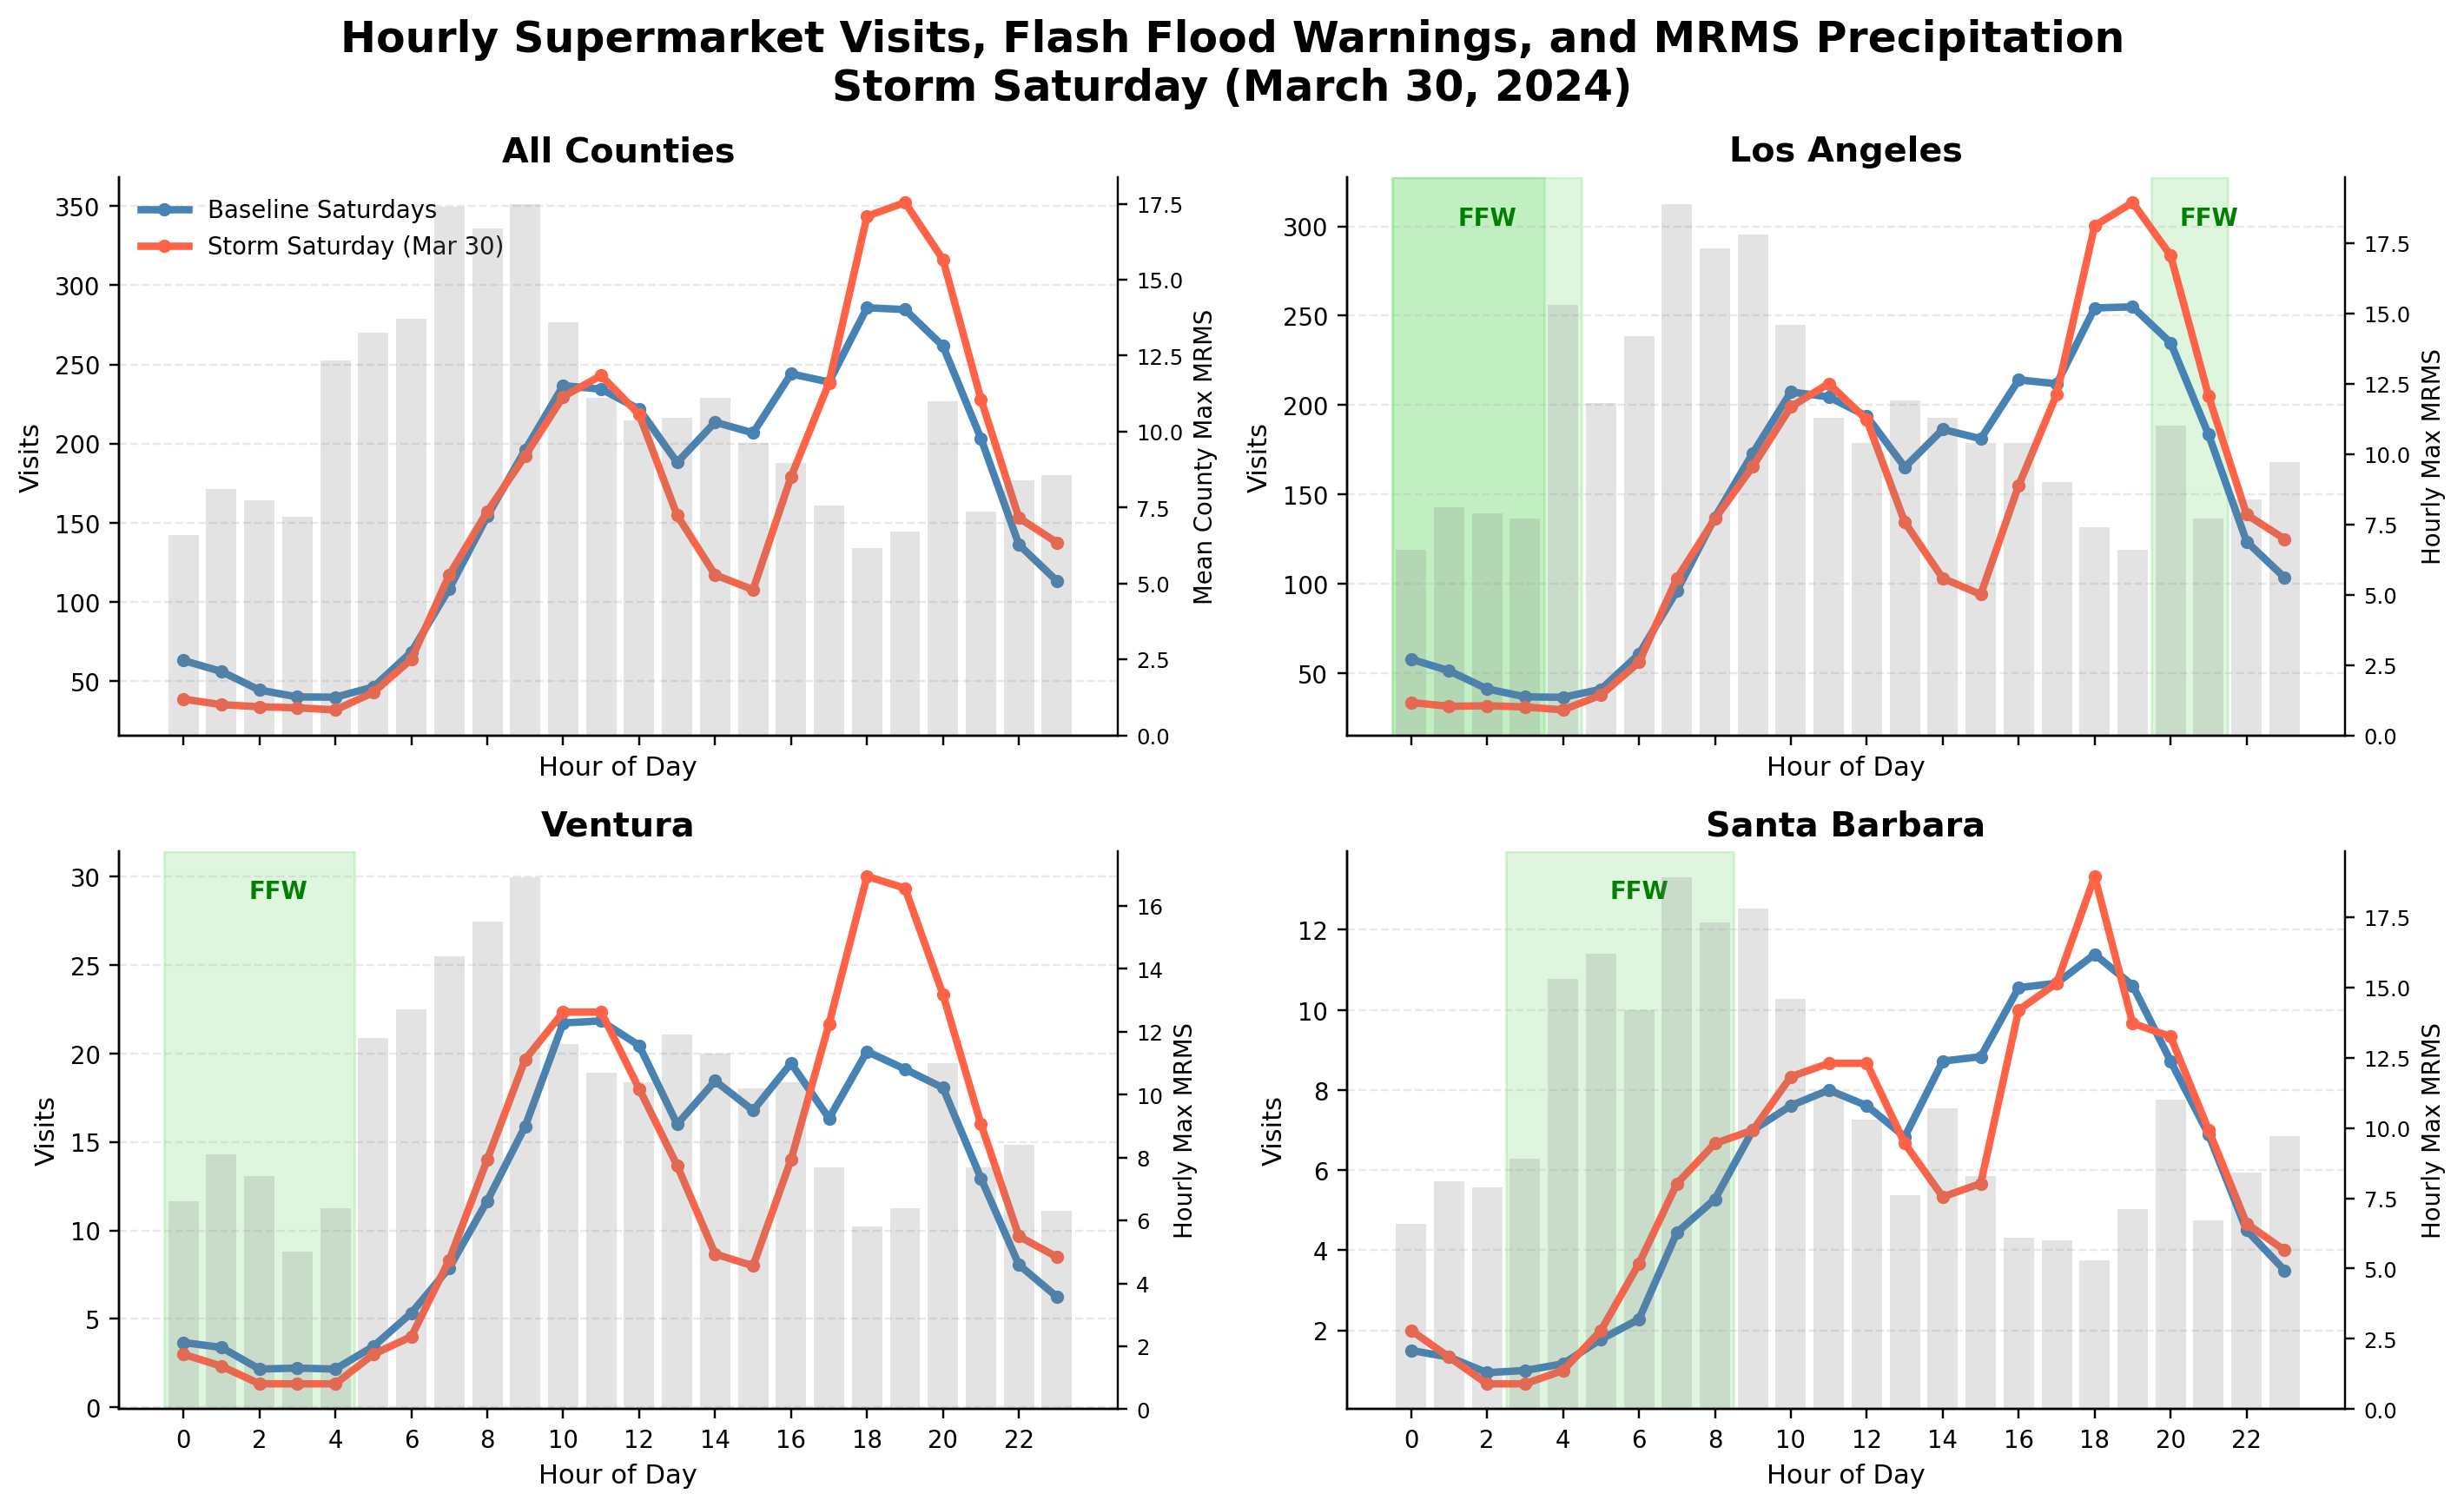

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), dpi=220, sharex=True)

panel_defs = [
    ("All Counties", None),
    ("Los Angeles", "Los Angeles"),
    ("Ventura", "Ventura"),
    ("Santa Barbara", "Santa Barbara")
]

for ax, (title, county_name) in zip(axes.flatten(), panel_defs):

    # -----------------------------
    # Behavior lines
    # -----------------------------
    b, s = hourly_visits_by_county(matched_named, county_name, storm_day)

    ax.plot(
        b.index, b.values,
        color="steelblue", linewidth=2.8, marker="o", markersize=4,
        label="Baseline Saturdays", zorder=3
    )
    ax.plot(
        s.index, s.values,
        color="tomato", linewidth=2.8, marker="o", markersize=4,
        label="Storm Saturday (Mar 30)", zorder=4
    )

    # -----------------------------
    # Secondary axis: MRMS bars
    # -----------------------------
    ax2 = ax.twinx()

    if county_name is None:
        precip = pd.concat(county_precip, axis=1).mean(axis=1)
        ax2.set_ylabel("Mean County Max MRMS", fontsize=9)
    else:
        precip = county_precip[county_name]
        ax2.set_ylabel("Hourly Max MRMS", fontsize=9)

    ax2.bar(
        precip.index,
        precip.values,
        width=0.8,
        color="gray",
        alpha=0.22,
        zorder=1
    )
    ax2.tick_params(axis="y", labelsize=8)
    ax2.spines["top"].set_visible(False)

    # -----------------------------
    # FFW shading + label
    # -----------------------------
    if county_name is not None:
        labeled_positions = []

        for start, end in ffw_windows_by_county[county_name]:
            if start.date() <= storm_day.date() <= end.date():
                start_h = 0 if start.date() < storm_day.date() else start.hour
                end_h = 24 if end.date() > storm_day.date() else end.hour + 1
                mid_h = (start_h + end_h) / 2

                ax.axvspan(
                    start_h - 0.5,
                    end_h - 0.5,
                    color="limegreen",
                    alpha=0.16,
                    zorder=0
                )

                if not any(abs(mid_h - prev) < 2 for prev in labeled_positions):
                    ax.text(
                        mid_h,
                        ax.get_ylim()[1] * 0.95,
                        "FFW",
                        color="green",
                        fontsize=9,
                        ha="center",
                        va="top",
                        weight="bold"
                    )
                    labeled_positions.append(mid_h)

    # -----------------------------
    # Formatting
    # -----------------------------
    ax.set_title(title, fontsize=13, weight="bold")
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("Hour of Day", fontsize=10)
    ax.set_ylabel("Visits", fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.28)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", labelsize=9)

axes[0, 0].legend(frameon=False, loc="upper left", fontsize=9)

fig.suptitle(
    "Hourly Supermarket Visits, Flash Flood Warnings, and MRMS Precipitation\nStorm Saturday (March 30, 2024)",
    fontsize=16, weight="bold"
)

plt.tight_layout()
plt.savefig("visits_ffw_mrms_bars_final.png", dpi=300, bbox_inches="tight")
plt.savefig("visits_ffw_mrms_bars_final.pdf", dpi=300, bbox_inches="tight", format="pdf")
plt.show()

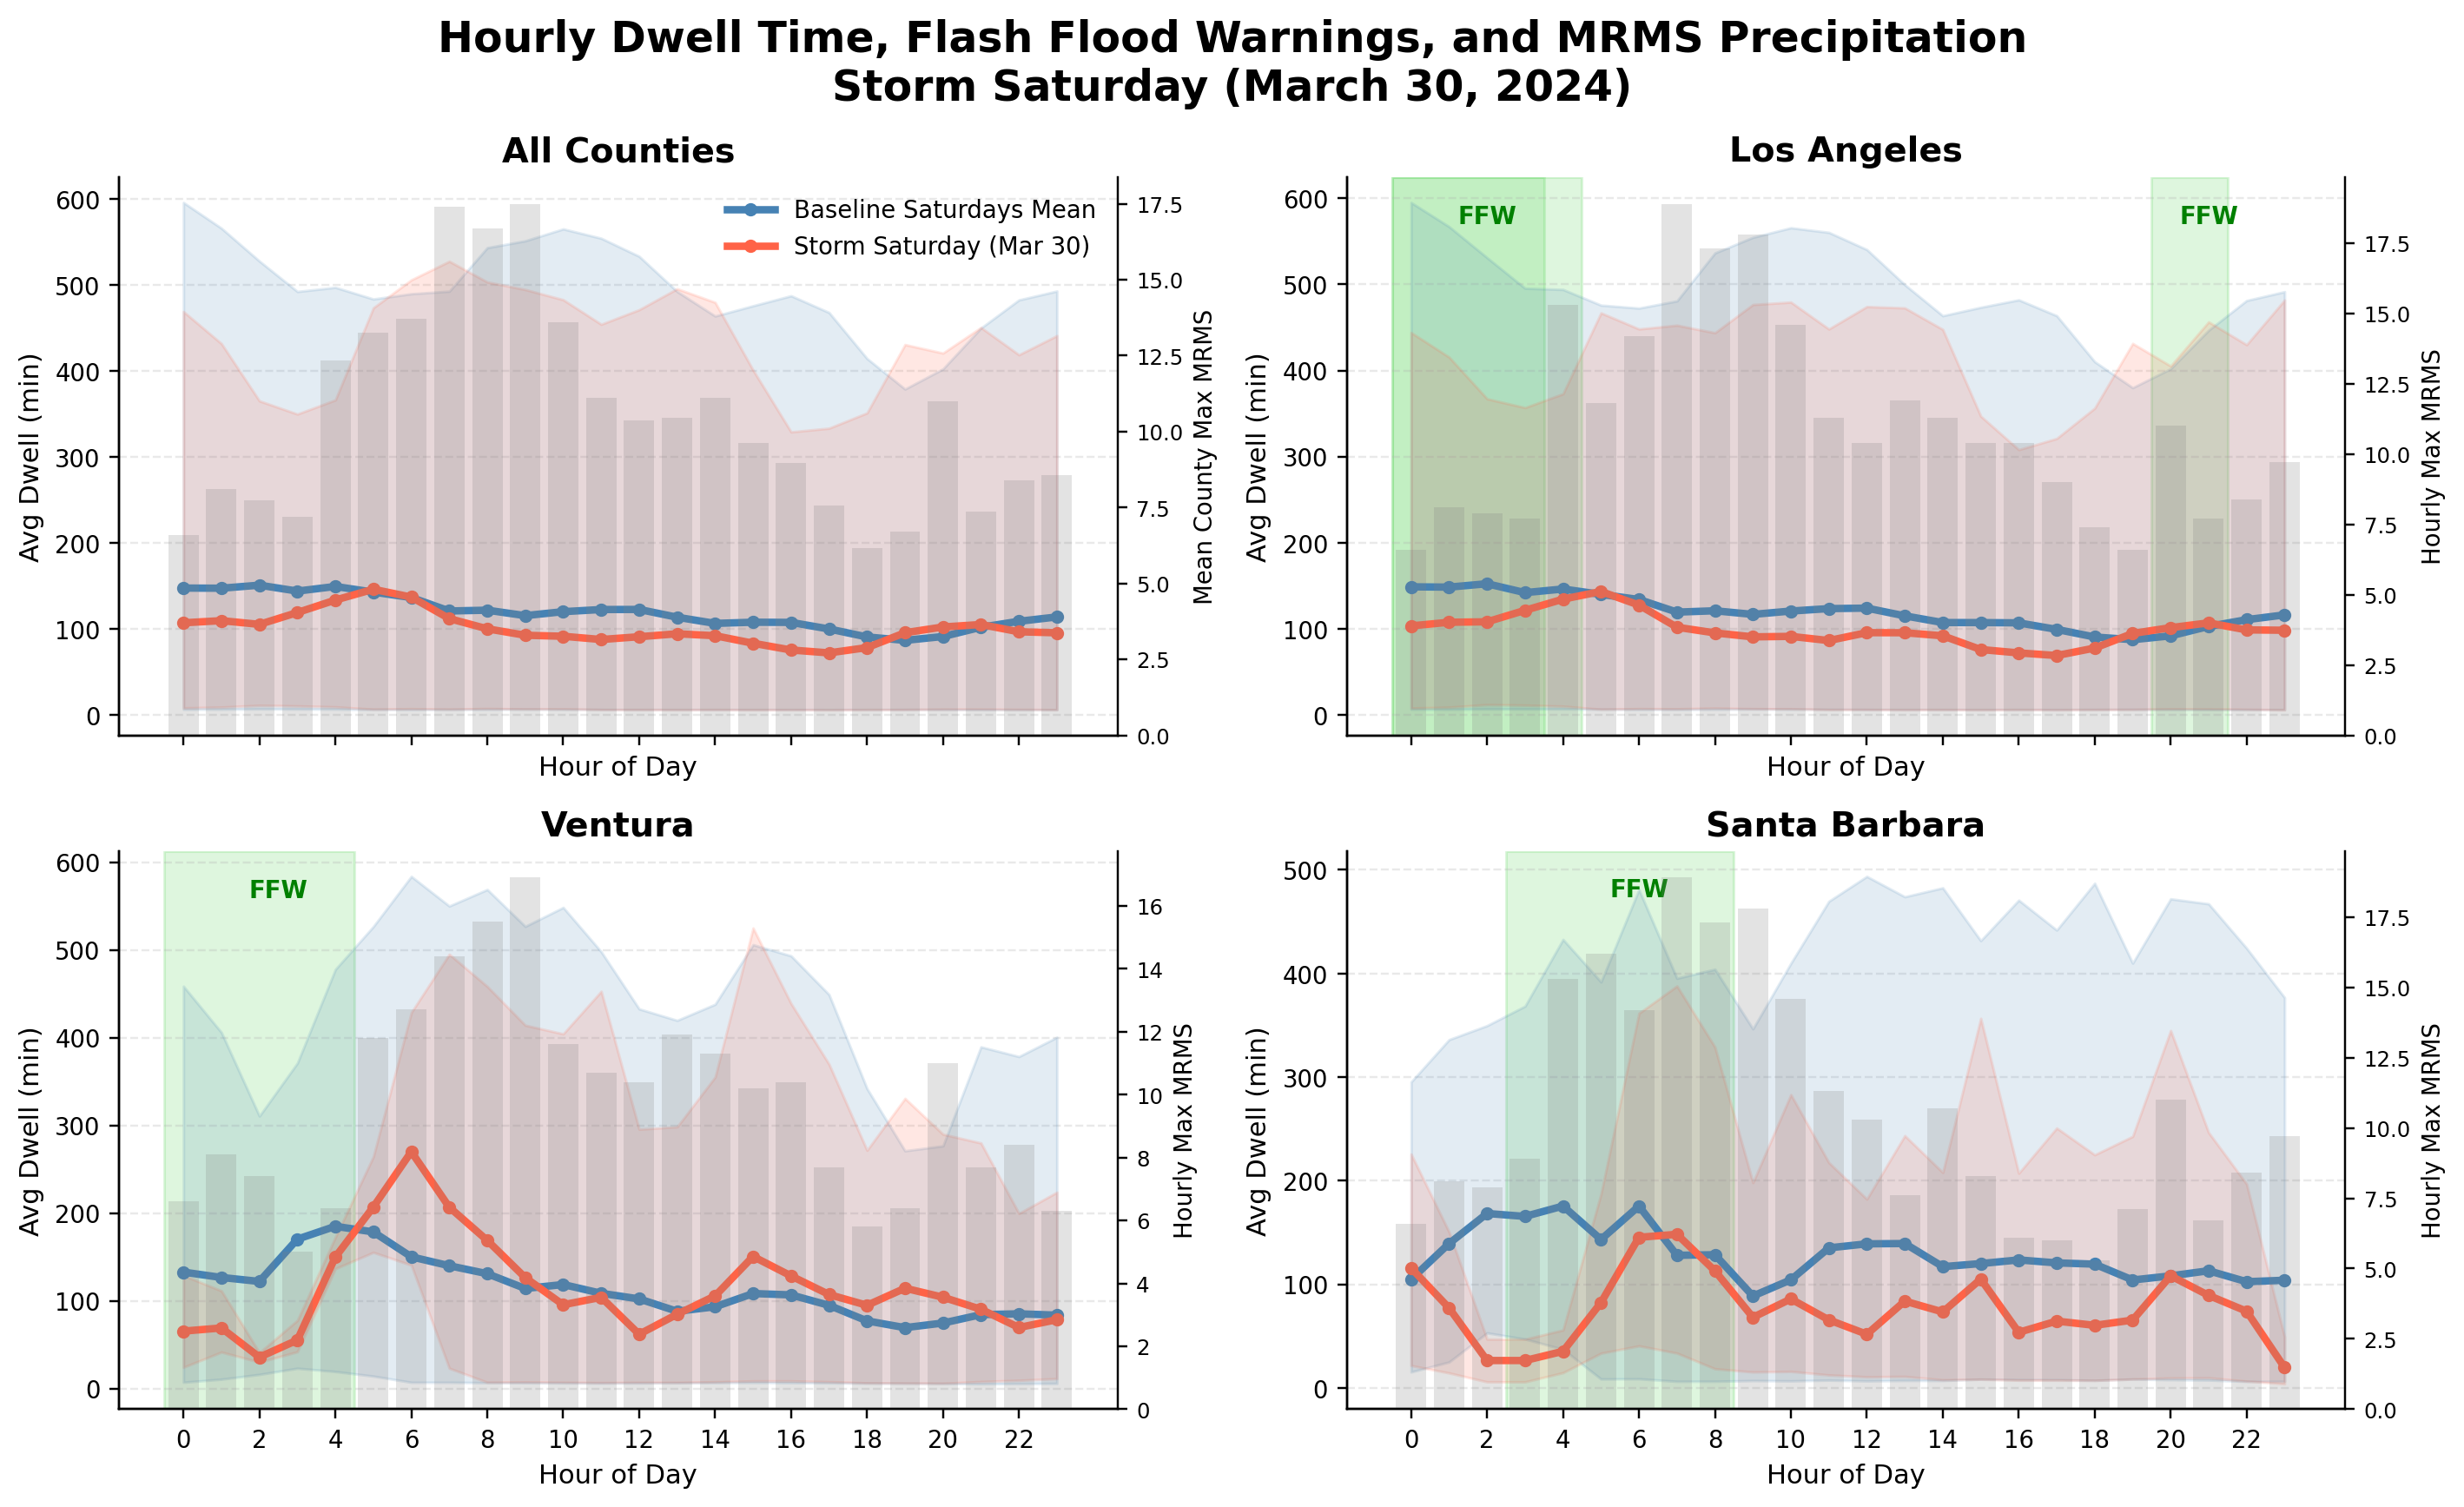

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), dpi=220, sharex=True)

panel_defs = [
    ("All Counties", None),
    ("Los Angeles", "Los Angeles"),
    ("Ventura", "Ventura"),
    ("Santa Barbara", "Santa Barbara")
]

for ax, (title, county_name) in zip(axes.flatten(), panel_defs):

    # -----------------------------
    # Behavior lines
    # -----------------------------
    b, b05, b95, s, s05, s95= hourly_dwell_by_county(matched_named, county_name, storm_day)

    ax.plot(
        b.index, b.values,
        color="steelblue", linewidth=2.8, marker="o", markersize=4,
        label="Baseline Saturdays Mean", zorder=5
    )
    ax.fill_between(
        b.index, b05.values, b95.values, color='steelblue',
        alpha=.15, zorder=3
    )
    ax.plot(
        s.index, s.values,
        color="tomato", linewidth=2.8, marker="o", markersize=4,
        label="Storm Saturday (Mar 30)", zorder=6
    )
    ax.fill_between(
        s.index, s05.values, s95.values, color='tomato',
        alpha=.15, zorder=4
    )
    
    # -----------------------------
    # Secondary axis: MRMS bars
    # -----------------------------
    ax2 = ax.twinx()

    if county_name is None:
        precip = pd.concat(county_precip, axis=1).mean(axis=1)
        ax2.set_ylabel("Mean County Max MRMS", fontsize=9)
    else:
        precip = county_precip[county_name]
        ax2.set_ylabel("Hourly Max MRMS", fontsize=9)

    ax2.bar(
        precip.index,
        precip.values,
        width=0.8,
        color="gray",
        alpha=0.22,
        zorder=1
    )
    ax2.tick_params(axis="y", labelsize=8)
    ax2.spines["top"].set_visible(False)

    # -----------------------------
    # FFW shading + label
    # -----------------------------
    if county_name is not None:
        labeled_positions = []

        for start, end in ffw_windows_by_county[county_name]:
            if start.date() <= storm_day.date() <= end.date():
                start_h = 0 if start.date() < storm_day.date() else start.hour
                end_h = 24 if end.date() > storm_day.date() else end.hour + 1
                mid_h = (start_h + end_h) / 2

                ax.axvspan(
                    start_h - 0.5,
                    end_h - 0.5,
                    color="limegreen",
                    alpha=0.16,
                    zorder=0
                )

                if not any(abs(mid_h - prev) < 2 for prev in labeled_positions):
                    ax.text(
                        mid_h,
                        ax.get_ylim()[1] * 0.95,
                        "FFW",
                        color="green",
                        fontsize=9,
                        ha="center",
                        va="top",
                        weight="bold"
                    )
                    labeled_positions.append(mid_h)

    # -----------------------------
    # Formatting
    # -----------------------------
    ax.set_title(title, fontsize=13, weight="bold")
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("Hour of Day", fontsize=10)
    ax.set_ylabel("Avg Dwell (min)", fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.28)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", labelsize=9)

axes[0, 0].legend(frameon=False, loc="upper right", fontsize=9)

fig.suptitle(
    "Hourly Dwell Time, Flash Flood Warnings, and MRMS Precipitation\nStorm Saturday (March 30, 2024)",
    fontsize=16, weight="bold"
)

plt.tight_layout()
plt.savefig("dwell_ffw_mrms_bars_final.png", dpi=300, bbox_inches="tight")
plt.savefig("dwell_ffw_mrms_bars_final.pdf", dpi=300, bbox_inches="tight", format="pdf")
plt.show()